# Where Honduras' pine harvest is authorized

A forest **operating plan** (*plan operativo anual*, POA) is the permit to harvest
one area of a forest management plan in a given year. ICF, the national forest
authority, publishes the approved POAs as a public map layer [@icf-planes-operativos],
and the department boundaries on the same server [@icf-limite-departamentos].

The question for today's theme: **does the authorized harvest spread out, or
does it gather in a few zones?** The answer is the second, and this notebook
shows where those zones are and how many of the plans each one gathers.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import patheffects
import numpy as np
import pandas as pd
from sklearn.cluster import HDBSCAN

WFS = "https://geoserver.icf.gob.hn/icfpub/wfs"
CRS = 32616  # WGS 84 / UTM zone 16N, the layer's own CRS, in metres


def read_layer(name: str) -> gpd.GeoDataFrame:
    """Read a whole layer from ICF's public WFS as GeoJSON."""
    url = (
        f"{WFS}?service=WFS&version=2.0.0&request=GetFeature"
        f"&typeNames={name}&outputFormat=application/json"
    )
    return gpd.read_file(url).to_crs(CRS)


raw = read_layer("planes_operativos_gp")
departments = read_layer("limite_departamentos_gp")
dates = pd.to_datetime(raw.fech_apro)
print(f"{len(raw):,} POA polygons, {dates.min():%d/%m/%Y} to {dates.max():%d/%m/%Y}")

1,729 POA polygons, 04/12/2017 to 28/09/2026


## Transform: one row per plan

A few `cod_poa` codes appear more than once: the same plan in several polygons.
Left as they are, that plan would count more than once, so its polygons are
merged into one plan.

In [2]:
raw["geometry"] = raw.geometry.make_valid()
repeated = raw.cod_poa.duplicated(keep=False)
print(f"{raw[repeated].cod_poa.nunique()} codes repeated in {repeated.sum()} polygons")

poa = raw.dissolve(
    by="cod_poa",
    aggfunc={
        "fech_apro": "first",
        "depto": "first",
        "tipo_bosq": "first",
        "tene_priv": "first",
        "tene_ejid": "first",
        "tene_naci": "first",
    },
).reset_index()
poa["year"] = pd.to_datetime(poa.fech_apro).dt.year
print(f"{len(poa):,} plans")

26 codes repeated in 52 polygons


1,703 plans


## A quick profile

In [3]:
tenure = (
    poa[["tene_priv", "tene_ejid", "tene_naci"]]
    .eq("SI")
    .mean()
    .rename({"tene_priv": "private", "tene_ejid": "ejidal", "tene_naci": "national"})
)
print("Share of plans by tenure (a plan can have more than one):")
print((tenure * 100).round(1).to_string())
print("\nForest type:")
print(poa.tipo_bosq.value_counts().to_string())

poa.groupby("year").size().rename("plans").to_frame().T

Share of plans by tenure (a plan can have more than one):
private     96.0
ejidal       2.4
national     1.6

Forest type:
tipo_bosq
Conifera       1686
Mixto            10
Latifoliado       7


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
plans,1,1,197,144,276,239,234,196,247,168


Almost every plan is in **pine** forest and on **private** land. The years
before 2019 hold only a couple of plans: the layer is, in practice, 2019 to
2026, and 2026 is still open.

## Clustering the plans

Each plan becomes one point (its polygon's centroid), and HDBSCAN groups the
points that sit close together [@campello2013], as implemented in scikit-learn
[@pedregosa2011]. Unlike k-means it does not need the number of groups in
advance, and it leaves isolated plans out as *noise*. Its one parameter is the
smallest group worth calling a cluster: here, **20 plans**.

In [4]:
MIN_CLUSTER = 20

points = np.c_[poa.centroid.x, poa.centroid.y]
poa["cluster"] = HDBSCAN(min_cluster_size=MIN_CLUSTER, copy=True).fit_predict(points)
print(f"{poa.cluster.max() + 1} clusters, {(poa.cluster < 0).sum()} plans outside them")

18 clusters, 496 plans outside them


## How concentrated are the plans?

Each cluster counts its plans, and its share is that count over all plans. On
the map, a cluster is drawn as the **concave hull** of its plans: the tightest
outline around them, labelled with the department where most of its plans are.

In [5]:
clusters = (
    poa[poa.cluster >= 0]
    .dissolve(
        by="cluster",
        aggfunc={
            "cod_poa": "size",
            "depto": lambda s: s.mode()[0],
        },
    )
    .rename(columns={"cod_poa": "plans", "depto": "department"})
)
clusters["geometry"] = clusters.geometry.concave_hull(ratio=0.3)
clusters["plan_share"] = clusters.plans / len(poa)
clusters = clusters.sort_values("plans", ascending=False, kind="stable")
clusters["rank"] = range(1, len(clusters) + 1)

TOP = 5
top = clusters.head(TOP)
print(
    f"{TOP} zones: {top.plans.sum()} of {len(poa):,} plans ({top.plan_share.sum():.0%})"
)
print(f"All {len(clusters)} clusters: {clusters.plan_share.sum():.0%} of the plans")
clusters[["rank", "department", "plans", "plan_share"]].round(3)

5 zones: 688 of 1,703 plans (40%)
All 18 clusters: 71% of the plans


,rank,department,plans,plan_share
cluster,,,,
14,1,Francisco Morazán,216,0.127
11,2,El Paraíso,178,0.105
8,3,Olancho,102,0.060
13,4,Olancho,96,0.056
16,5,Olancho,96,0.056
3,6,Intibucá,81,0.048
1,7,Santa Bárbara,58,0.034
4,8,Yoro,50,0.029
12,9,Olancho,49,0.029


### Does the finding depend on the parameter?

A result that only holds for one setting is not a result. The same measure with
smaller and larger clusters:

In [6]:
rows = []
for size in (10, 20, 40):
    labels = HDBSCAN(min_cluster_size=size, copy=True).fit_predict(points)
    plans = pd.Series(labels[labels >= 0]).value_counts()
    rows.append(
        {
            "min_cluster_size": size,
            "clusters": len(plans),
            f"top {TOP} plan share": plans.nlargest(TOP).sum() / len(poa),
        }
    )
pd.DataFrame(rows).round(3)

,min_cluster_size,clusters,top 5 plan share
0,10,27,0.353
1,20,18,0.404
2,40,4,0.844


With 10 or 20 plans per cluster the picture holds: the five largest zones gather
35 to 40% of the plans (figures as of 2026-11-04). At 40 the clusters
merge into a few regional blobs and stop being zones, so 20 is the setting used.

## The map

The same map in English and Spanish: only the text changes.

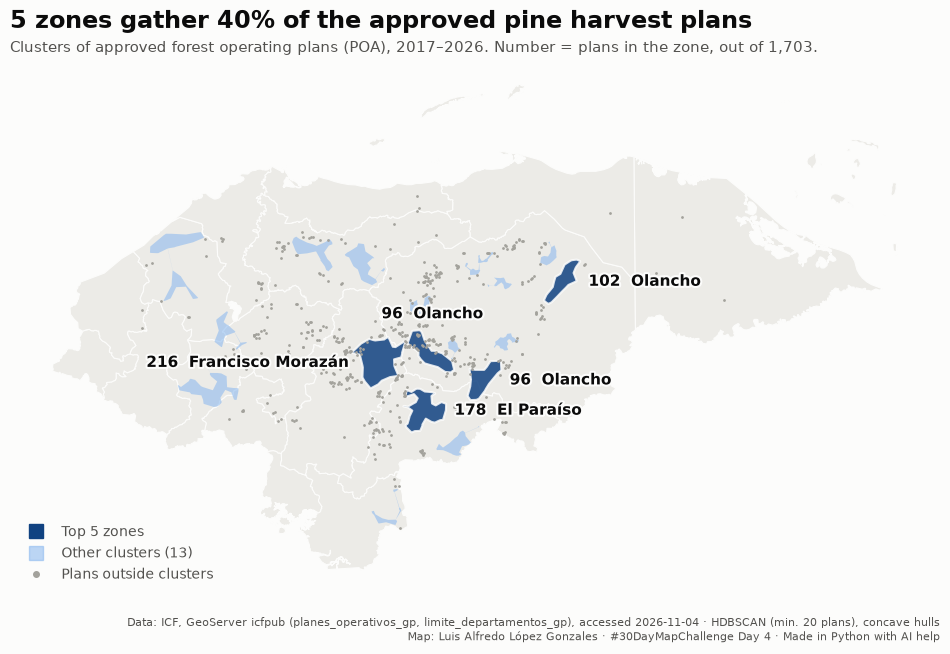

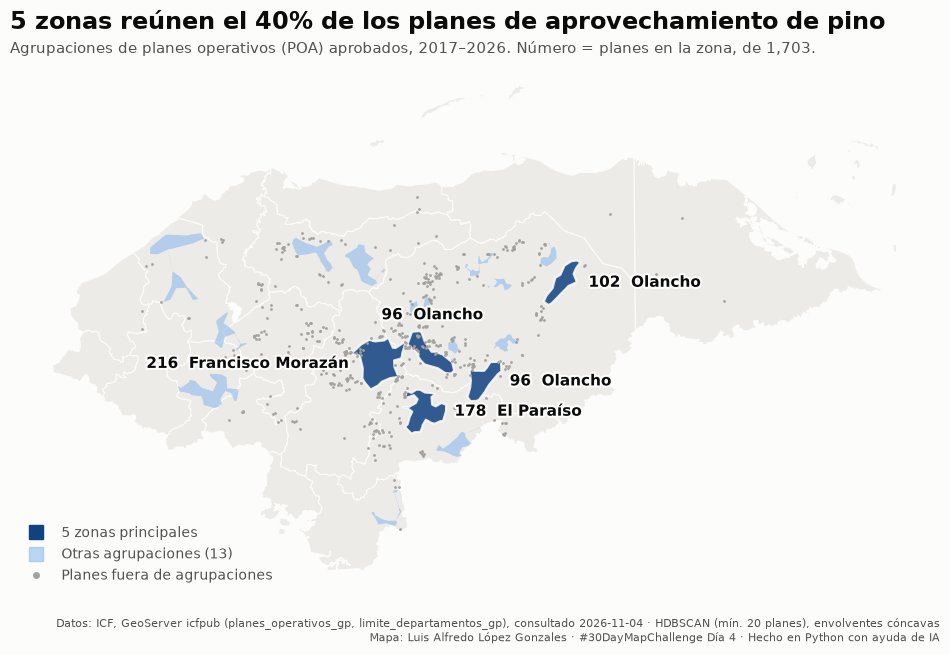

In [7]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#a3a29c"
SURFACE, LAND, EDGE = "#fcfcfb", "#ecebe7", "#fcfcfb"
HOT, OTHER = "#104281", "#86b6ef"

top_share = top.plan_share.sum()
first_year, others = poa.year.min(), len(clusters) - TOP
TEXT = {
    "en": {
        "title": f"{TOP} zones gather {top_share:.0%} of the approved pine harvest plans",
        "subtitle": f"Clusters of approved forest operating plans (POA), {first_year}–2026. "
        f"Number = plans in the zone, out of {len(poa):,}.",
        "top": f"Top {TOP} zones",
        "other": f"Other clusters ({others})",
        "outside": "Plans outside clusters",
        "credits": "Data: ICF, GeoServer icfpub (planes_operativos_gp, "
        "limite_departamentos_gp), accessed 2026-11-04 · HDBSCAN (min. 20 plans), concave hulls\n"
        "Map: Luis Alfredo López Gonzales · #30DayMapChallenge Day 4 · "
        "Made in Python with AI help",
    },
    "es": {
        "title": f"{TOP} zonas reúnen el {top_share:.0%} de los planes de aprovechamiento de pino",
        "subtitle": f"Agrupaciones de planes operativos (POA) aprobados, {first_year}–2026. "
        f"Número = planes en la zona, de {len(poa):,}.",
        "top": f"{TOP} zonas principales",
        "other": f"Otras agrupaciones ({others})",
        "outside": "Planes fuera de agrupaciones",
        "credits": "Datos: ICF, GeoServer icfpub (planes_operativos_gp, "
        "limite_departamentos_gp), consultado 2026-11-04 · HDBSCAN (mín. 20 planes), envolventes cóncavas\n"
        "Mapa: Luis Alfredo López Gonzales · #30DayMapChallenge Día 4 · "
        "Hecho en Python con ayuda de IA",
    },
}

# Label side per zone rank, set by eye for the data of 2026-11-04 so the
# central labels don't cross; any other rank goes to the right.
LABEL_SIDE = {1: "left", 5: "top"}


def draw_map(lang: str) -> plt.Figure:
    """Draw the zone map with its text in `lang` ("en" or "es")."""
    text = TEXT[lang]
    fig, ax = plt.subplots(figsize=(12, 8), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    departments.simplify(200).plot(ax=ax, color=LAND, edgecolor=EDGE, linewidth=0.8)
    clusters.iloc[TOP:].plot(ax=ax, color=OTHER, alpha=0.55, edgecolor="none")
    top.plot(ax=ax, color=HOT, alpha=0.85, edgecolor=SURFACE, linewidth=1.5)
    outside = poa[poa.cluster < 0]
    ax.scatter(outside.centroid.x, outside.centroid.y, s=4, color=MUTED, linewidths=0)

    for _, row in top.iterrows():
        minx, miny, maxx, maxy = row.geometry.bounds
        side = LABEL_SIDE.get(row["rank"], "right")
        xy, offset, ha, va = {
            "right": ((maxx, (miny + maxy) / 2), (6, 0), "left", "center"),
            "left": ((minx, (miny + maxy) / 2), (-6, 0), "right", "center"),
            "top": (((minx + maxx) / 2, maxy), (0, 6), "center", "bottom"),
        }[side]
        ax.annotate(
            f"{row.plans}  {row.department}",
            xy=xy,
            xytext=offset,
            textcoords="offset points",
            ha=ha,
            va=va,
            fontsize=11,
            fontweight="bold",
            color=INK,
            path_effects=[patheffects.withStroke(linewidth=3, foreground=SURFACE)],
        )

    ax.text(
        0.0,
        1.06,
        text["title"],
        transform=ax.transAxes,
        fontsize=17,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        0.0, 1.015, text["subtitle"], transform=ax.transAxes, fontsize=10.5, color=INK_2
    )

    handles = [
        plt.Line2D([], [], marker="s", ls="", ms=10, color=HOT, label=text["top"]),
        plt.Line2D(
            [],
            [],
            marker="s",
            ls="",
            ms=10,
            color=OTHER,
            alpha=0.55,
            label=text["other"],
        ),
        plt.Line2D([], [], marker="o", ls="", ms=4, color=MUTED, label=text["outside"]),
    ]
    ax.legend(
        handles=handles, loc="lower left", frameon=False, fontsize=10, labelcolor=INK_2
    )
    ax.text(
        1.0,
        -0.04,
        text["credits"],
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color=INK_2,
    )

    ax.set_axis_off()
    ax.set_aspect("equal")
    return fig


for lang in TEXT:
    fig = draw_map(lang)
    fig.savefig(
        f"day04-clusters-{lang}.png", dpi=200, bbox_inches="tight", facecolor=SURFACE
    )
plt.show()

## References

::: {#refs}
:::